# Phase 1: Define the study areas

**Objective:** consistent geographical boundaries for both regions (SRS Phase 1).

1. Download municipal or administrative boundaries.
2. Open them in QGIS (done by you, at the end).
3. Check their coordinate reference system.
4. Repair invalid geometries if required.
5. Save both boundaries as GeoJSON.
6. Create a combined study-area boundary.
7. Use the same projection and spatial grid for all later processing.

**Output:** `data/boundaries/mumbai.geojson`, `navi_mumbai.geojson`, `combined_study_area.geojson`.
**Completion:** both boundaries display correctly in QGIS.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))

from urban_heat import boundaries as b, config
from urban_heat.grid import Grid, save_grids
config.ensure_dirs()
print('project folder:', config.ROOT)

project folder: C:\Users\yedve\codeprojects\urban-heat-risk-prediction


## Step 1: Download the boundaries
Source: OpenStreetMap administrative boundaries (SRS assumption A1).
- **Mumbai** = Greater Mumbai = Mumbai City district + Mumbai Suburban district.
- **Navi Mumbai** = the OSM administrative boundary of Navi Mumbai.

The largest polygon matching each name is chosen automatically. If a choice is wrong, set the osm ids from the printed list in `MUMBAI_IDS` / `NAVI_MUMBAI_IDS`.

In [2]:
MUMBAI_IDS = None        # e.g. [7964376, 7964375]
NAVI_MUMBAI_IDS = None   # e.g. [13180880]

mumbai_candidates = b.search('Mumbai City district') + b.search('Mumbai Suburban district')
navi_candidates = b.search('Navi Mumbai')
print('Mumbai candidates:'); b.show(mumbai_candidates)
print('Navi Mumbai candidates:'); b.show(navi_candidates)

mumbai_pick = (b.pick(mumbai_candidates, MUMBAI_IDS) if MUMBAI_IDS
               else b.pick_largest_by_prefix(mumbai_candidates, ['Mumbai City', 'Mumbai Suburban']))
navi_pick = (b.pick(navi_candidates, NAVI_MUMBAI_IDS) if NAVI_MUMBAI_IDS
             else b.pick_largest_by_prefix(navi_candidates, ['Navi Mumbai']))
print('\nchosen:', [f['properties']['display_name'][:45] for f in mumbai_pick + navi_pick])

Mumbai candidates:
[0] relation 7964376  boundary/administrative  MultiPolygon  ~71 km2  Mumbai City District, Maharashtra, India
[1] relation 7964375  boundary/administrative  MultiPolygon  ~403 km2  Mumbai Suburban District, Maharashtra, India
Navi Mumbai candidates:
[0] relation 13180880  boundary/administrative  Polygon  ~105 km2  Navi Mumbai, Thane Subdistrict, Thane, Maharashtra, India

chosen: ['Mumbai City District, Maharashtra, India', 'Mumbai Suburban District, Maharashtra, India', 'Navi Mumbai, Thane Subdistrict, Thane, Mahara']


## Steps 3 and 4: Check validity, repair if needed
Downloaded GeoJSON from OpenStreetMap is in WGS84 (EPSG:4326, longitude/latitude).

In [3]:
mumbai, mumbai_prov = b.boundary_from_features(mumbai_pick, name='Mumbai',
                                               query='Mumbai City district + Mumbai Suburban district')
navi, navi_prov = b.boundary_from_features(navi_pick, name='Navi Mumbai', query='Navi Mumbai')
for name, geom, prov in [('Mumbai', mumbai, mumbai_prov), ('Navi Mumbai', navi, navi_prov)]:
    print(f"{name}: {geom.geom_type}, ~{b.approx_area_km2(geom):.0f} km2, "
          f"validity before: {prov['validity_before_repair']}, repaired: {prov['repaired']}, now valid: {geom.is_valid}")

Mumbai: MultiPolygon, ~474 km2, validity before: valid, repaired: False, now valid: True
Navi Mumbai: Polygon, ~105 km2, validity before: valid, repaired: False, now valid: True


## Steps 5 and 6: Save both boundaries and the combined study area
Each file gets a `.meta.json` beside it recording its source, so the chosen boundary is documented precisely.

In [4]:
m_path = b.save_boundary(mumbai, config.BOUNDARIES / 'mumbai.geojson', name='Mumbai', provenance=mumbai_prov)
n_path = b.save_boundary(navi, config.BOUNDARIES / 'navi_mumbai.geojson', name='Navi Mumbai', provenance=navi_prov)
c_path = b.combine([m_path, n_path], config.BOUNDARIES / 'combined_study_area.geojson')
for p in (m_path, n_path, c_path):
    print(p.relative_to(config.ROOT), '| CRS:', b.geojson_crs(p), '| valid:', b.load(p).is_valid)

data\boundaries\mumbai.geojson | CRS: EPSG:4326 | valid: True
data\boundaries\navi_mumbai.geojson | CRS: EPSG:4326 | valid: True
data\boundaries\combined_study_area.geojson | CRS: EPSG:4326 | valid: True


## Step 7: One projection and spatial grid for all later processing
Projection: UTM zone 43N (EPSG:32643), which covers both cities, in metres. Two grids over the combined study area (+2 km margin), snapped to whole cells, saved to `data/grids.json`:
- `modis_1km` for MODIS LST and the model,
- `landsat_30m` for the detailed Landsat maps.

In [5]:
combined_utm = b.to_crs(b.load(c_path), b.WGS84, config.CRS)
grids = {
    'modis_1km': Grid.covering(combined_utm, res=config.MODIS_RES_M, margin_m=config.GRID_MARGIN_M, crs=config.CRS),
    'landsat_30m': Grid.covering(combined_utm, res=config.LANDSAT_RES_M, margin_m=config.GRID_MARGIN_M, crs=config.CRS),
}
save_grids(grids, config.DATA / 'grids.json')
for k, g in grids.items():
    print(f'{k}: {g.width} x {g.height} cells at {g.res:.0f} m, bounds {g.bounds}')

utm = {'mumbai': b.to_crs(mumbai, b.WGS84, config.CRS), 'navi_mumbai': b.to_crs(navi, b.WGS84, config.CRS)}
g = grids['modis_1km']
masks = {k: g.cell_mask(v) for k, v in utm.items()}
for k, m in masks.items():
    print(f'{k}: {int(m.sum())} cells of 1 km inside the boundary')
print('overlap between cities:', int((masks['mumbai'] & masks['navi_mumbai']).sum()), 'cells')

modis_1km: 34 x 47 cells at 1000 m, bounds (263000.0, 2088000.0, 297000.0, 2135000.0)
landsat_30m: 1100 x 1525 cells at 30 m, bounds (263760.0, 2088300.0, 296760.0, 2134050.0)


mumbai: 470 cells of 1 km inside the boundary
navi_mumbai: 103 cells of 1 km inside the boundary
overlap between cities: 0 cells


## Figure 1.1: The two study-area boundaries
**What it shows:** the saved Mumbai (Greater Mumbai: Mumbai City + Mumbai Suburban districts) and Navi Mumbai boundaries, drawn in longitude and latitude (WGS84, the coordinate system of the GeoJSON files). The legend gives each area in km2.

**How to read it:** the two cities are separated by Thane Creek. Small separate shapes are islands that belong to the administrative boundary.

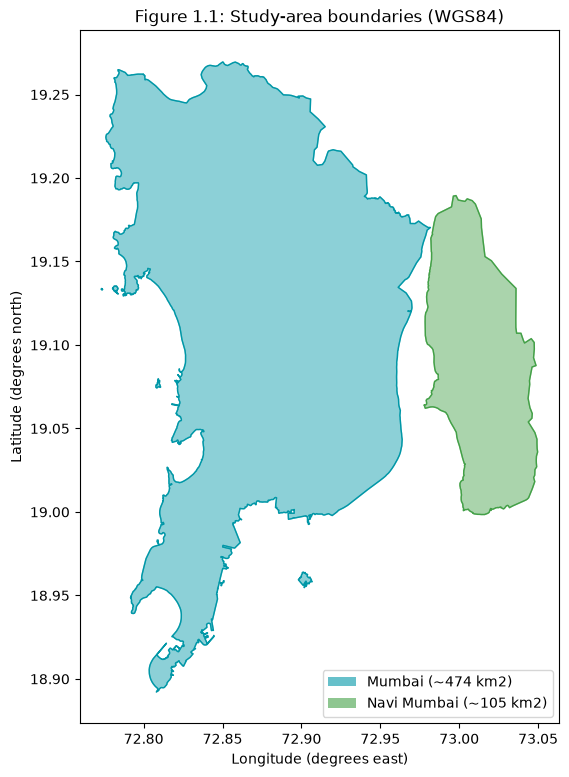

In [6]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
fig, ax = plt.subplots(figsize=(8, 9))
handles = []
for geom, colour, label in [(mumbai, '#0097a7', 'Mumbai'), (navi, '#43a047', 'Navi Mumbai')]:
    for poly in getattr(geom, 'geoms', [geom]):
        ax.fill(*poly.exterior.xy, alpha=0.45, color=colour)
        ax.plot(*poly.exterior.xy, color=colour, lw=1)
    handles.append(Patch(facecolor=colour, alpha=0.6, label=f'{label} (~{b.approx_area_km2(geom):.0f} km2)'))
ax.legend(handles=handles, loc='lower right')
ax.set_xlabel('Longitude (degrees east)'); ax.set_ylabel('Latitude (degrees north)')
ax.set_aspect(1 / np.cos(np.radians(19.1)))          # equal ground distance in x and y
ax.set_title('Figure 1.1: Study-area boundaries (WGS84)')
fig.savefig(config.OUTPUTS / 'charts' / 'fig1_1_boundaries.png', dpi=130, bbox_inches='tight'); plt.show()

## Figure 1.2: The common 1 km grid and which cells belong to each city
**What it shows:** the 1 km analysis grid in UTM zone 43N (axes in km). A cell is coloured when at least half of it lies inside a city; the outlines are the exact boundaries. The legend gives the number of 1 km cells per city.

**How to read it:** every later MODIS and ERA5-Land layer uses exactly these cells, so a value in row r, column c always refers to the same 1 km x 1 km piece of ground.

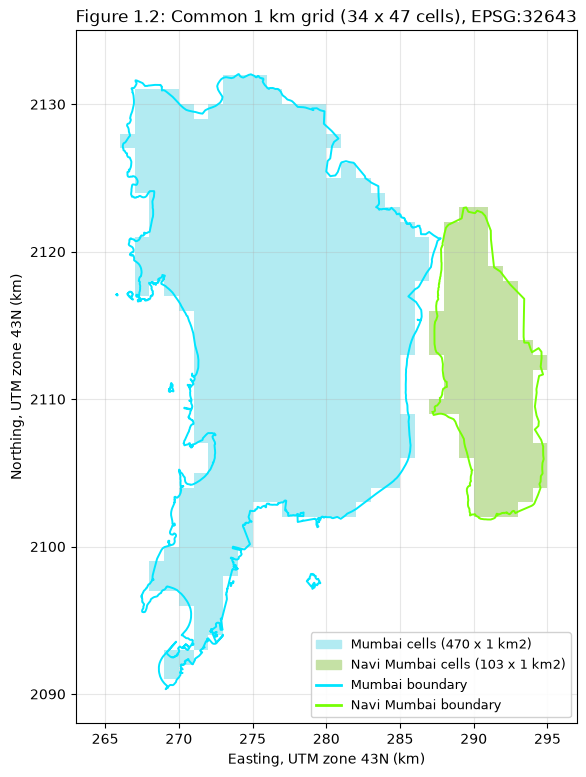

In [7]:
from urban_heat import plotting as Pl
from matplotlib.colors import ListedColormap
canvas = np.full(g.shape, np.nan)
canvas[masks['mumbai']] = 1; canvas[masks['navi_mumbai']] = 2
fig, ax = plt.subplots(figsize=(8, 9))
ax.imshow(canvas, extent=Pl.extent_km(g), cmap=ListedColormap(['#b2ebf2', '#c5e1a5']), vmin=1, vmax=2, interpolation='nearest')
Pl.draw_cities(ax, utm, extra_handles=[
    Patch(color='#b2ebf2', label=f"Mumbai cells ({int(masks['mumbai'].sum())} x 1 km2)"),
    Patch(color='#c5e1a5', label=f"Navi Mumbai cells ({int(masks['navi_mumbai'].sum())} x 1 km2)")])
Pl.map_axes(ax, f'Figure 1.2: Common 1 km grid ({g.width} x {g.height} cells), EPSG:32643')
ax.grid(alpha=0.3)
fig.savefig(config.OUTPUTS / 'charts' / 'fig1_2_grid_cells.png', dpi=130, bbox_inches='tight'); plt.show()

## Step 2 and completion: check in QGIS
1. Open QGIS, add a basemap: *Browser panel > XYZ Tiles > OpenStreetMap* (drag it into the map).
2. Drag in `data/boundaries/mumbai.geojson`, `navi_mumbai.geojson` and `combined_study_area.geojson`.
3. Check: Mumbai covers the island city and suburbs up to Dahisar/Mulund; Navi Mumbai sits east of Thane Creek; the edges follow the coastline and creek on the basemap.

If a boundary is wrong, set the osm ids in step 1 and re-run this notebook. Close the files in QGIS before re-running, or Windows will refuse to overwrite them.